In [1]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [2]:
uploaded = files.upload()

Saving housing dataset.csv to housing dataset.csv


In [3]:
filename = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[filename]))

print(f"Loaded '{filename}' successfully with shape: {df.shape}")
df.head()

Loaded 'housing dataset.csv' successfully with shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41,880,129.0,322,126,8.3252,"$452,600.00",NEAR BAY
1,-122.22,37.86,21,7099,1106.0,2401,1138,8.3014,"$358,500.00",NEAR BAY
2,-122.24,37.85,52,1467,190.0,496,177,7.2574,"$352,100.00",NEAR BAY
3,-122.25,37.85,52,1274,235.0,558,219,5.6431,"$341,300.00",NEAR BAY
4,-122.25,37.85,52,1627,280.0,565,259,3.8462,"$342,200.00",NEAR BAY


In [48]:
print("--- Missing Values Per Column ---")
print(df.isnull().sum())
print("\n--- Data Info ---")
print(df.info())

--- Missing Values Per Column ---
longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64

--- Data Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  int64  
 3   total_rooms         20640 non-null  int64  
 4   total_bedrooms      20640 non-null  float64
 5   population          20640 non-null  int64  
 6   households          20640 non-null  int64  
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  object 
 9   ocean_proximity     20640 non-null  objec

In [43]:
df_fe = df.copy()
# 1. Strip whitespace from column names
df_fe.columns = df_fe.columns.str.strip()

# 2. Clean 'median_house_value' (removes $, commas, spaces, currency codes)
df_fe['median_house_value'] = (
    df_fe['median_house_value']
    .astype(str)
    .str.replace(r'[^\d.-]', '', regex=True)
)
df_fe['median_house_value'] = pd.to_numeric(df_fe['median_house_value'], errors='coerce')
df_fe = df_fe.dropna(subset=['median_house_value']).reset_index(drop=True)

# 3. Impute the 207 missing values in 'total_bedrooms' with median
df_fe['total_bedrooms'] = df_fe['total_bedrooms'].fillna(df_fe['total_bedrooms'].median())

# 4. Engineer ratio & interaction features safely
df_fe['rooms_per_household'] = df_fe['total_rooms'] / df_fe['households'].replace(0, np.nan)
df_fe['bedrooms_per_room'] = df_fe['total_bedrooms'] / df_fe['total_rooms'].replace(0, np.nan)
df_fe['population_per_household'] = df_fe['population'] / df_fe['households'].replace(0, np.nan)
df_fe['income_x_rooms'] = df_fe['median_income'] * df_fe['rooms_per_household']

# Fill any division edge-case NaNs with column medians
df_fe = df_fe.fillna(df_fe.median(numeric_only=True))

# 5. Check Variance Inflation Factor (VIF) on numeric predictors
target_col = 'median_house_value'
X_temp = df_fe.drop(columns=[target_col]).select_dtypes(include=[np.number])

vif_data = pd.DataFrame({
    "Feature": X_temp.columns,
    "VIF": [variance_inflation_factor(X_temp.values, i) for i in range(X_temp.shape[1])]
})
print("--- Variance Inflation Factor (VIF) ---")
print(vif_data.sort_values(by="VIF", ascending=False))

# 6. Drop raw redundant count columns
cols_to_drop = ['total_rooms', 'total_bedrooms', 'population']
df_fe = df_fe.drop(columns=cols_to_drop)

print(f"\nSuccess! Final shape: {df_fe.shape}, Missing values: {df_fe.isnull().sum().sum()}")

--- Variance Inflation Factor (VIF) ---
                     Feature        VIF
4             total_bedrooms  35.755574
6                 households  34.872440
11            income_x_rooms  17.847902
3                total_rooms  16.476120
7              median_income  12.298736
1                   latitude   9.372000
0                  longitude   9.100031
5                 population   6.725094
8        rooms_per_household   5.314263
9          bedrooms_per_room   2.262665
2         housing_median_age   1.262168
10  population_per_household   1.065700

Success! Final shape: (20640, 11), Missing values: 0


In [46]:
df_fe.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0
rooms_per_household,0
bedrooms_per_room,0
population_per_household,0


In [47]:
# Clean column names directly on df as well
df.columns = df.columns.str.strip()

# Impute the 207 missing values in 'total_bedrooms' directly on df
df['total_bedrooms'] = df['total_bedrooms'].fillna(df['total_bedrooms'].median())

# Verify missing values are now 0 across the entire dataset
print("--- Missing Values in df After Imputation ---")
print(df.isnull().sum())

print("\n--- Missing Values in df_fe (Engineered Dataset) ---")
print(df_fe.isnull().sum())

--- Missing Values in df After Imputation ---
longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64

--- Missing Values in df_fe (Engineered Dataset) ---
longitude                   0
latitude                    0
housing_median_age          0
households                  0
median_income               0
median_house_value          0
ocean_proximity             0
rooms_per_household         0
bedrooms_per_room           0
population_per_household    0
income_x_rooms              0
dtype: int64


In [49]:
plt.figure(figsize=(10, 8))
numeric_df = df.select_dtypes(include=[np.number])
corr_matrix = numeric_df.corr()

<Figure size 1000x800 with 0 Axes>

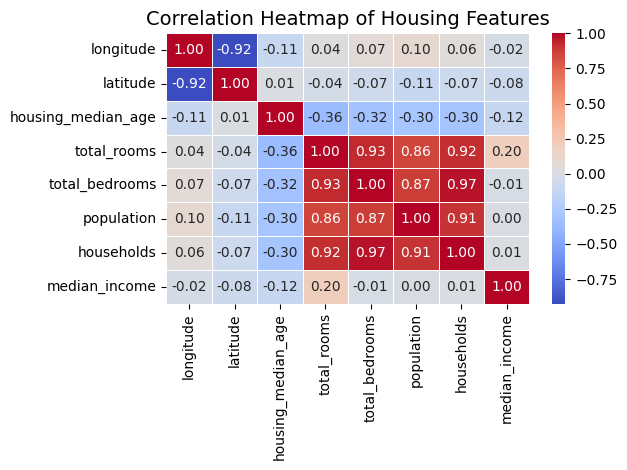

In [50]:
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Heatmap of Housing Features", fontsize=14)
plt.tight_layout()
plt.show()

In [52]:
# Separate features (X) and target (y)
X = df_fe.drop(columns=[target_col])
y = df_fe[target_col]

# Identify numerical and categorical columns dynamically
num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X.select_dtypes(exclude=[np.number]).columns.tolist()

print("Numerical features:", num_cols)
print("Categorical features:", cat_cols)

# Train-test split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Build preprocessing pipelines
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, num_cols),
        ('cat', categorical_transformer, cat_cols)
    ]
)

# Fit and transform training data; transform test data
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print(f"Processed training shape: {X_train_processed.shape}")

Numerical features: ['longitude', 'latitude', 'housing_median_age', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_x_rooms']
Categorical features: ['ocean_proximity']
Processed training shape: (16512, 13)


In [53]:
# Define hyperparameter grid for Ridge and Lasso
alpha_grid = {'alpha': [0.001, 0.01, 0.1, 1.0, 10.0, 50.0, 100.0, 500.0, 1000.0]}

# 1. Ordinary Least Squares (OLS)
ols_model = LinearRegression()
ols_model.fit(X_train_processed, y_train)

# 2. Ridge Regression (L2) with GridSearchCV
ridge_grid = GridSearchCV(Ridge(random_state=42), param_grid=alpha_grid, cv=5, scoring='neg_root_mean_squared_error')
ridge_grid.fit(X_train_processed, y_train)
best_ridge = ridge_grid.best_estimator_

# 3. Lasso Regression (L1) with GridSearchCV
lasso_grid = GridSearchCV(Lasso(max_iter=10000, random_state=42), param_grid=alpha_grid, cv=5, scoring='neg_root_mean_squared_error')
lasso_grid.fit(X_train_processed, y_train)
best_lasso = lasso_grid.best_estimator_

print(f"Best Ridge Alpha: {ridge_grid.best_params_['alpha']}")
print(f"Best Lasso Alpha: {lasso_grid.best_params_['alpha']}\n")

# Evaluate all three models on the test set
models = {
    'OLS (Linear Regression)': ols_model,
    f"Ridge (alpha={ridge_grid.best_params_['alpha']})": best_ridge,
    f"Lasso (alpha={lasso_grid.best_params_['alpha']})": best_lasso
}

results = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test_processed)
    predictions[name] = y_pred

    rmse = root_mean_squared_error(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    results.append({
        'Model': name,
        'RMSE': round(rmse, 2),
        'MAE': round(mae, 2),
        'R² Score': round(r2, 4)
    })

results_df = pd.DataFrame(results)
print("--- Model Performance Comparison ---")
display(results_df)

Best Ridge Alpha: 1.0
Best Lasso Alpha: 1.0

--- Model Performance Comparison ---


,Model,RMSE,MAE,R² Score
0,OLS (Linear Regression),75818.17,52907.96,0.5613
1,Ridge (alpha=1.0),75824.14,52915.17,0.5613
2,Lasso (alpha=1.0),75817.97,52908.59,0.5613


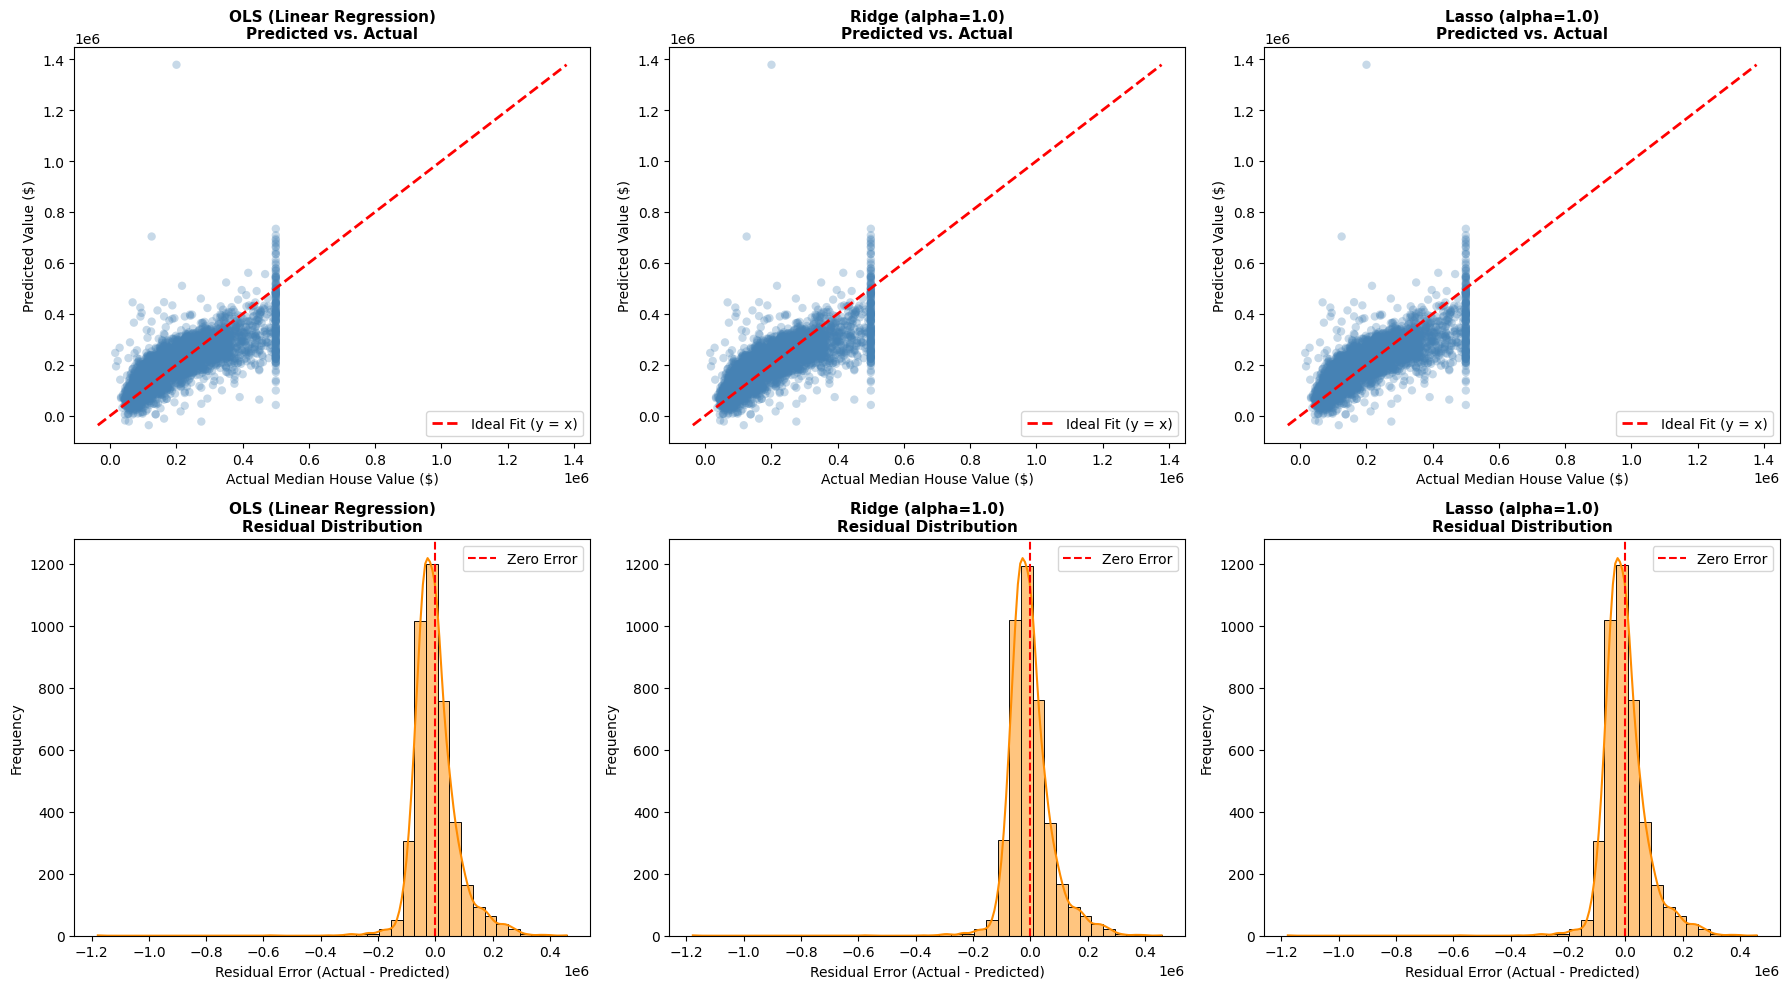

In [54]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 10))
model_names = list(predictions.keys())

for idx, name in enumerate(model_names):
    y_pred = predictions[name]
    residuals = y_test - y_pred

    # Row 1: Predicted vs Actual Values
    ax_scatter = axes[0, idx]
    ax_scatter.scatter(y_test, y_pred, alpha=0.3, color='steelblue', edgecolors='none')
    min_val = min(y_test.min(), y_pred.min())
    max_val = max(y_test.max(), y_pred.max())
    ax_scatter.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Ideal Fit (y = x)')
    ax_scatter.set_title(f"{name}\nPredicted vs. Actual", fontsize=11, fontweight='bold')
    ax_scatter.set_xlabel("Actual Median House Value ($)")
    ax_scatter.set_ylabel("Predicted Value ($)")
    ax_scatter.legend()

    # Row 2: Residual Distribution Curve
    ax_resid = axes[1, idx]
    sns.histplot(residuals, kde=True, bins=40, color='darkorange', ax=ax_resid)
    ax_resid.axvline(0, color='red', linestyle='--', lw=1.5, label='Zero Error')
    ax_resid.set_title(f"{name}\nResidual Distribution", fontsize=11, fontweight='bold')
    ax_resid.set_xlabel("Residual Error (Actual - Predicted)")
    ax_resid.set_ylabel("Frequency")
    ax_resid.legend()

plt.tight_layout()
plt.show()

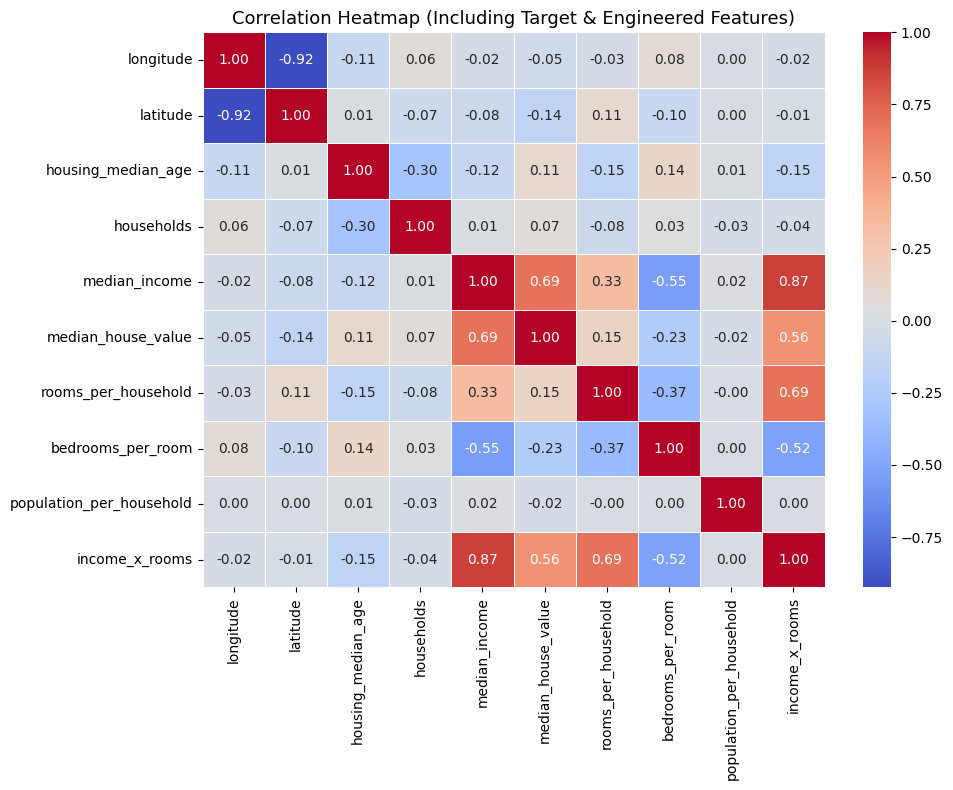

In [55]:
plt.figure(figsize=(10, 8))
sns.heatmap(df_fe.select_dtypes(include=[np.number]).corr(), annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Heatmap (Including Target & Engineered Features)", fontsize=13)
plt.tight_layout()
plt.show()